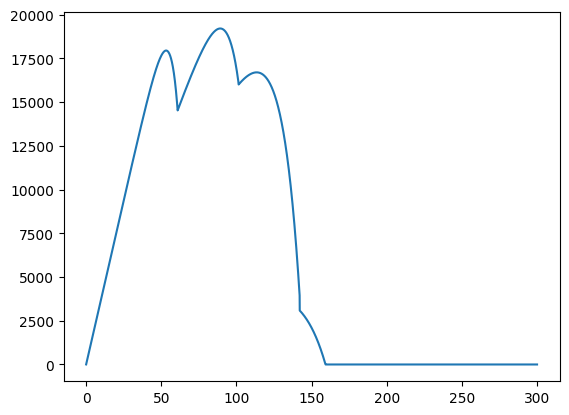

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

class Shaded(object):
    def __init__(self):
        self.G = [100, 1000]  # read irradiance # Solar radiation in mW / sq.cm / Esto es la irradiancia para panel cuando [sombredo,sin_sombra]
        #self.T = 25  # read temperature # ojo con kelvin 273
        #self.SH = [4, 10, 7, 10, 10, 10]  # Shaded modules
        self.Mp = 10  # Modules in parallel
        self.Ng = [40, 38, 22]  # Parallel-connected series assemblies
        self.Iscr_sh = 0.375

    def data(self, Irradiancia_maxima, T, V, SH):

        # G_ar = np.array(G) # Solar radiation in mW/sq.cm

        pv = Panel()
        IUN = []
        ISH = []
        Ipv = []

        for j in range(len(self.Ng)):
            # IUN_i = pv.calc_pv(Irradiancia_maxima, T, V, SH[j*2])[0] # asi estaria bien hecho, pero como dejamos fija la irradiancia maxima lo tomamos del self.G[1]
            IUN_i = pv.calc_pv(self.G[1], T, V, SH[j*2])[0]
            if IUN_i < 0:
                IUN_i = 0
            IUN.append(IUN_i)
            ISH_i = pv.calc_pv(self.G[0], T, V, SH[j*2+1])[0]
            if ISH_i< 0:
                ISH_i = 0
            ISH.append(ISH_i)

        for jj in (range(len(self.Ng))):
            if IUN[jj] > self.Iscr_sh:
                Ipv.append(IUN[jj])
            else:
                Ipv.append(ISH[jj])

        
        IT = Ipv[0] * self.Ng[0] + Ipv[1] * self.Ng[1] + Ipv[2] * self.Ng[2]
        VT = V
        PT = IT*VT
        return IT, VT, PT 

class Panel(object):

    def __init__(self):
        self.TK = 273 # Kelvin temperature
        self.Tr1 = 40  # Reference temperature in degree fahrenheit
        # self.S = 100  # Solar radiation in mW / sq.cm
        self.ki = 0.00023  # in A / K
        self.Iscr = 3.75  # SC Current at ref.temp. in A
        self.Irr = 0.000021  # in A
        self.k = 1.38065e-23  # Boltzmann constant
        self.q = 1.6022e-19  # charge of an electron
        self.A = 2.15 # ideality factor
        self.Eg0 = 1.166 # band gap energy
        self.alpha = 0.473
        self.beta = 636
        # panel composed of Np parallel modules each one including Ns photovoltaic cells connected
        self.Np = 1
        self.Ns = 36

    def calc_pv(self, G, T, vx, SH):
        # cell temperature
        Tcell = T + self.TK
        # cell reference temperature in kelvin
        Tr = ((self.Tr1 - 32) * (5 / 9)) + 273
        # band gap energy of semiconductor
        Eg = self.Eg0 - (self.alpha * Tcell * Tcell) / (Tcell + self.beta) * self.q
        # generated photocurrent
        Iph = (self.Iscr + self.ki * (Tcell - Tr)) * (G / 1000)
        # cell reverse saturation current
        Irs = self.Irr * ((Tcell / Tr) ** 3) * np.exp(self.q * Eg / (self.k * self.A) * ((1 / Tr) - (1 / Tcell)))
        # panel output current
        I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)
        # panel output voltage
        V = vx # este es el Vg?
        # panel power
        P = vx * I

        return I,V,P

                
Voltage = 0.
Power = 0.
Temp = 25.
Irr = 1000.
# a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
a = 3
b = 7
c = 5
SH = [a, 10, b, 10, c, 10]

powerlst = []
voltagelst = []

for i in range(30000):
    Voltage += 0.01
    pv = Shaded()
    Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
    powerlst.append(Power)
    voltagelst.append(Voltage)

plt.plot(voltagelst, powerlst)

In [4]:
Vmax = np.zeros((11, 11, 11))
for i in range(1, 11):
    for j in range(1, 11):
        for k in range(1, 11):
            Voltage = 0.
            Power = 0.
            Temp = 25.
            Irr = 1000.
            a, b, c = i, j, k
            SH = [a, 10, b, 10, c, 10]
            powerlst = []
            voltagelst = []
            for ite in range(21200):
                Voltage += 0.01
                pv = Shaded()
                Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
                powerlst.append(Power)
                voltagelst.append(Voltage)
            Pmax = max(powerlst)
            max_index = powerlst.index(Pmax)
            Vmax[i][j][k] = round(voltagelst[max_index], 2)
            print(i, j, k, Vmax[i][j][k])

1 1 1 16.11
1 1 2 16.55
1 1 3 16.56
1 1 4 66.55
1 1 5 83.01
1 1 6 99.08
1 1 7 114.07
1 1 8 126.57
1 1 9 135.03
1 1 10 139.57
1 2 1 16.96
1 2 2 32.45
1 2 3 34.01
1 2 4 34.08
1 2 5 83.01
1 2 6 99.08
1 2 7 114.07
1 2 8 126.57
1 2 9 135.03
1 2 10 139.57
1 3 1 49.14
1 3 2 35.86
1 3 3 48.68
1 3 4 50.86
1 3 5 51.07
1 3 6 51.11
1 3 7 114.07
1 3 8 126.57
1 3 9 135.03
1 3 10 139.57
1 4 1 65.49
1 4 2 65.49
1 4 3 53.37
1 4 4 64.89
1 4 5 67.57
1 4 6 68.0
1 4 7 68.1
1 4 8 68.14
1 4 9 68.15
1 4 10 68.16
1 5 1 81.78
1 5 2 81.78
1 5 3 81.78
1 5 4 70.55
1 5 5 81.08
1 5 6 84.15
1 5 7 84.83
1 5 8 85.03
1 5 9 85.1
1 5 10 85.12
1 6 1 97.88
1 6 2 97.88
1 6 3 97.88
1 6 4 71.69
1 6 5 87.45
1 6 6 97.19
1 6 7 100.55
1 6 8 101.49
1 6 9 101.8
1 6 10 101.92
1 7 1 113.44
1 7 2 113.44
1 7 3 113.44
1 7 4 113.44
1 7 5 89.22
1 7 6 104.04
1 7 7 113.06
1 7 8 116.6
1 7 9 117.78
1 7 10 118.21
1 8 1 127.64
1 8 2 127.64
1 8 3 127.64
1 8 4 127.64
1 8 5 89.73
1 8 6 106.44
1 8 7 120.13
1 8 8 128.33
1 8 9 131.83
1 8 10 133.16
1 9

7 6 6 100.43
7 6 7 103.37
7 6 8 104.15
7 6 9 104.4
7 6 10 104.49
7 7 1 112.9
7 7 2 112.9
7 7 3 112.9
7 7 4 112.9
7 7 5 92.68
7 7 6 106.28
7 7 7 112.78
7 7 8 114.82
7 7 9 115.46
7 7 10 115.69
7 8 1 117.99
7 8 2 117.99
7 8 3 117.99
7 8 4 117.99
7 8 5 117.99
7 8 6 108.13
7 8 7 116.59
7 8 8 119.58
7 8 9 120.53
7 8 10 120.86
7 9 1 119.85
7 9 2 119.85
7 9 3 119.85
7 9 4 119.85
7 9 5 119.85
7 9 6 108.72
7 9 7 117.88
7 9 8 121.26
7 9 9 122.33
7 9 10 122.71
7 10 1 120.54
7 10 2 120.54
7 10 3 120.54
7 10 4 120.54
7 10 5 120.54
7 10 6 108.95
7 10 7 118.35
7 10 8 121.87
7 10 9 122.99
7 10 10 123.38
8 1 1 127.73
8 1 2 127.73
8 1 3 127.73
8 1 4 127.73
8 1 5 89.97
8 1 6 106.69
8 1 7 120.32
8 1 8 128.37
8 1 9 131.77
8 1 10 133.05
8 2 1 127.73
8 2 2 127.73
8 2 3 127.73
8 2 4 127.73
8 2 5 89.97
8 2 6 106.69
8 2 7 120.32
8 2 8 128.37
8 2 9 131.77
8 2 10 133.05
8 3 1 127.73
8 3 2 127.73
8 3 3 127.73
8 3 4 127.73
8 3 5 89.97
8 3 6 106.69
8 3 7 120.32
8 3 8 128.37
8 3 9 131.77
8 3 10 133.05
8 4 1 127.73
8 4

In [5]:
print(Vmax)

[[[  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.     0.     0.   ...   0.     0.     0.  ]
  ...
  [  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.     0.     0.   ...   0.     0.     0.  ]]

 [[  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.    16.11  16.55 ... 126.57 135.03 139.57]
  [  0.    16.96  32.45 ... 126.57 135.03 139.57]
  ...
  [  0.   127.64 127.64 ... 128.33 131.83 133.16]
  [  0.   139.05 139.05 ... 135.18 142.14 145.24]
  [  0.   146.55 146.55 ... 138.31 148.03 153.14]]

 [[  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.    17.02  32.43 ... 126.57 135.03 139.57]
  [  0.    32.32  32.22 ... 126.57 135.03 139.57]
  ...
  [  0.   127.64 127.64 ... 128.33 131.83 133.16]
  [  0.   139.05 139.05 ... 135.18 142.14 145.24]
  [  0.   146.55 146.55 ... 138.31 148.03 153.14]]

 ...

 [[  0.     0.     0.   ...   0.     0.     0.  ]
  [  0.   127.73 127

In [6]:
np.save('Vmax.npy', Vmax)
# Pmax = np.load('Pmax.npy')